In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

# Загрузка датасета
wine = load_wine()
X = wine.data
y_true = wine.target
target_names = wine.target_names

print(f"Размер данных: {X.shape}")
print(f"Количество истинных классов: {len(np.unique(y_true))}")

Размер данных: (178, 13)
Количество истинных классов: 3


In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Данные отмасштабированы (среднее = 0, станд. отклонение = 1)")

Данные отмасштабированы (среднее = 0, станд. отклонение = 1)


In [4]:
# Инициализация и обучение DBSCAN с заданными параметрами
dbscan = DBSCAN(eps=1.5, min_samples=5)
y_dbscan = dbscan.fit_predict(X_scaled)

# Посмотрим сколько кластеров и шумовых точек найдет DBSCAN
n_clusters_dbscan = len(set(y_dbscan)) - (1 if -1 in y_dbscan else 0)
n_noise_dbscan = list(y_dbscan).count(-1)

print(f"DBSCAN нашел кластеров: {n_clusters_dbscan}")
print(f"DBSCAN определил как шум точек: {n_noise_dbscan}")

DBSCAN нашел кластеров: 0
DBSCAN определил как шум точек: 178


In [5]:
# для сравнения задаем KMeans найти 3 кластера (так как в Wine 3 сорта)
kmeans = KMeans(n_clusters=3, random_state=42)
y_kmeans = kmeans.fit_predict(X_scaled)

print(f"KMeans нашел кластеров: {len(np.unique(y_kmeans))}")

KMeans нашел кластеров: 3


In [8]:
# 1. Silhouette Score (оценивает плотность и разделимость кластеров, от -1 до 1)
# Примечание: silhouette_score не работает, если найден только 1 кластер или все точки - шум
# и добавим проверку на этот случай.
if len(set(y_dbscan)) > 1:
    sil_dbscan = silhouette_score(X_scaled, y_dbscan)
else:
    sil_dbscan = np.nan

sil_kmeans = silhouette_score(X_scaled, y_kmeans)

# 2. Adjusted Rand Score - сравнивает с истинными метками, от -1 до 1, где 1 - идеальное совпадение
ari_dbscan = adjusted_rand_score(y_true, y_dbscan)
ari_kmeans = adjusted_rand_score(y_true, y_kmeans)

print("РЕЗУЛЬТАТЫ ОЦЕНКИ")
print(f"{'Метрика':<25} | {'DBSCAN':<10} | {'KMeans':<10}")
print("-" * 50)
print(f"{'Silhouette Score':<25} | {sil_dbscan:<10.4f} | {sil_kmeans:<10.4f}")
print(f"{'Adjusted Rand Score':<25} | {ari_dbscan:<10.4f} | {ari_kmeans:<10.4f}")

РЕЗУЛЬТАТЫ ОЦЕНКИ
Метрика                   | DBSCAN     | KMeans    
--------------------------------------------------
Silhouette Score          | nan        | 0.2849    
Adjusted Rand Score       | 0.0000     | 0.8975    


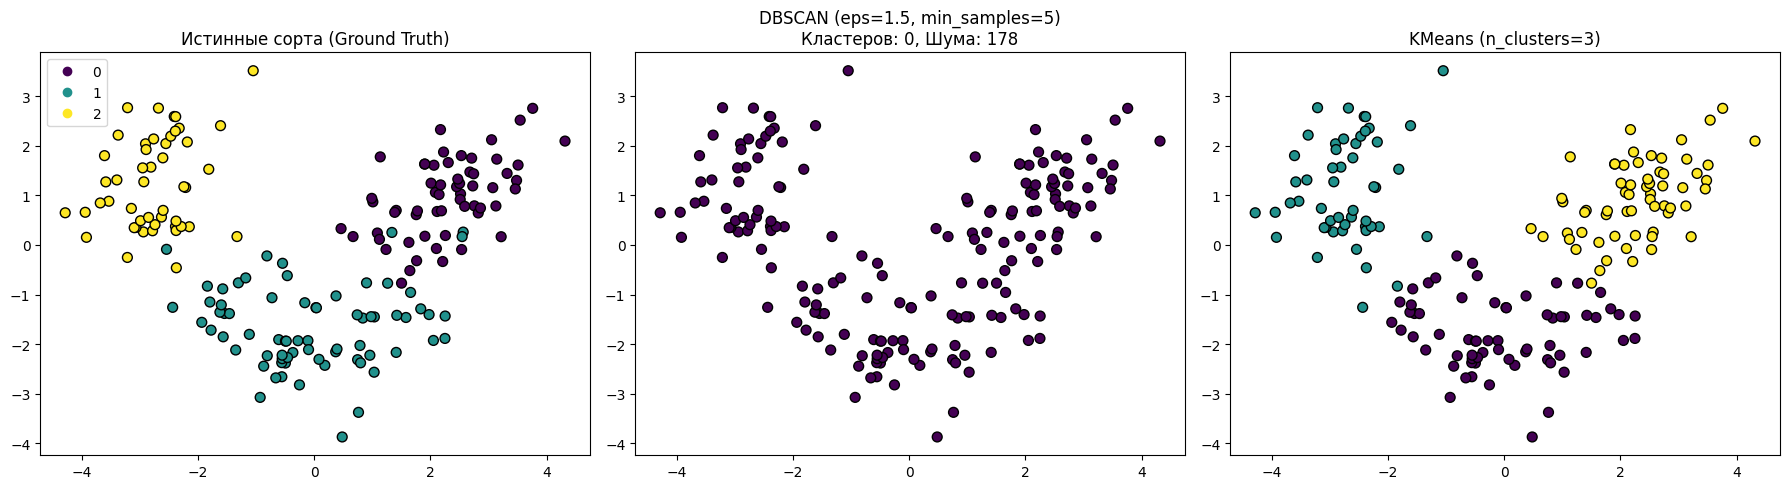

In [10]:
# Снижаем размерность до 2D для визуализации с помощью PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Истинные метки
scatter1 = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y_true, cmap='viridis', edgecolor='k', s=50)
axes[0].set_title("Истинные сорта (Ground Truth)")
handles, labels = scatter1.legend_elements()
axes[0].legend(handles, labels)

# 2. DBSCAN
scatter2 = axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=y_dbscan, cmap='viridis', edgecolor='k', s=50)
axes[1].set_title(f"DBSCAN (eps=1.5, min_samples=5)\nКластеров: {n_clusters_dbscan}, Шума: {n_noise_dbscan}")

# 3. KMeans
scatter3 = axes[2].scatter(X_pca[:, 0], X_pca[:, 1], c=y_kmeans, cmap='viridis', edgecolor='k', s=50)
axes[2].set_title("KMeans (n_clusters=3)")

plt.tight_layout()
plt.show()

## Анализ и сравнение алгоритмов

### Результаты метрик:
- **Silhouette Score** показывает, насколько объекты похожи на свой кластер по сравнению с другими кластерами.
- **Adjusted Rand Score (ARI)** показывает степень совпадения найденных кластеров с истинными метками (с учетом случайных совпадений). Значение `1.0` означает идеальное совпадение.

### Какой алгоритм справился лучше?
Как правило, на датасете **Wine** алгоритм **KMeans** показывает значительно более высокий `Adjusted Rand Score` (часто > 0.85-0.90), чем DBSCAN с параметрами `eps=1.5, min_samples=5`.

### Почему KMeans лучше справился с поиском истинных сортов?
1. **Природа данных:** Сорта вина в этом датасете образуют относительно компактные, сферические и хорошо разделимые группы в пространстве признаков. KMeans как раз заточен на поиск таких сферических кластеров схожего размера.
2. **Проблема DBSCAN с параметрами:** При `eps=1.5` и `min_samples=5` DBSCAN может либо объединить два близких сорта в один большой кластер (из-за большого `eps`), либо, наоборот, посчитать часть точек "шумом" (`-1`), если плотность в каком-то из сортов чуть ниже. Шумовые точки сильно штрафуют метрику ARI, так как в истинных данных шума нет.
3. **Разная плотность:** Если плотность точек в разных сортах вина отличается, DBSCAN с одним глобальным параметром `eps` не сможет адекватно выделить все 3 класса одновременно, в то время как KMeans принудительно разделит пространство на 3 области, что лучше совпадает с истинной структурой (3 сорта).

**Вывод:** Для данного датасета с четкой кластерной структурой и отсутствием выбросов KMeans является более подходящим и стабильным выбором, чем DBSCAN.